In [1]:
import requests
import pandas as pd

BASE = "https://api.openf1.org/v1"

def get(endpoint, **params):
    r = requests.get(f"{BASE}/{endpoint}", params=params, timeout=30)
    r.raise_for_status()
    return pd.DataFrame(r.json())

# 1) Yarışın session_key değerini bul
sessions = get("sessions", year=2024, country_name="Bahrain", session_name="Race")
print(sessions[["session_key", "session_name", "country_name", "date_start"]])
session_key = int(sessions.loc[0, "session_key"])

# 2) Turlar ve lastik stintleri
laps = get("laps", session_key=session_key)
stints = get("stints", session_key=session_key)

print("Tur sayısı:", len(laps), "| Stint sayısı:", len(stints))
laps.head()

   session_key session_name country_name                 date_start
0         9472         Race      Bahrain  2024-03-02T15:00:00+00:00
Tur sayısı: 1129 | Stint sayısı: 63


,meeting_key,session_key,driver_number,lap_number,date_start,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,is_pit_out_lap,lap_duration,segments_sector_1,segments_sector_2,segments_sector_3,st_speed
0,1229,9472,1,1,2024-03-02T15:03:42.341000+00:00,32.877,41.266,23.616,234.0,250,False,97.759,"[None, 2048, 2049, 2049, 2051, 2051, 2049, 204...","[2051, 2051, 2051, 2049, 2049, 2049, 2049, 205...","[2051, 2051, 2049, 2049, 2051, 2049, 2051]",251.0
1,1229,9472,16,1,2024-03-02T15:03:42.341000+00:00,33.495,41.549,23.635,232.0,252,False,98.679,"[None, 2048, 2049, 2051, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2051, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2051]",255.0
2,1229,9472,63,1,2024-03-02T15:03:42.341000+00:00,33.889,42.099,23.694,225.0,252,False,99.682,"[None, 2048, 2049, 2049, 2049, 2049, 2051, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2051]",256.0
3,1229,9472,44,1,2024-03-02T15:03:42.341000+00:00,35.450,43.609,24.393,229.0,246,False,103.452,"[2048, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2051, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2049]",249.0
4,1229,9472,55,1,2024-03-02T15:03:42.341000+00:00,34.408,42.861,23.765,233.0,249,False,101.034,"[None, 2048, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2051, 2049, 2051, 2051]",256.0


In [2]:
df = laps.merge(stints, on="driver_number", suffixes=("", "_stint"))
df = df[(df.lap_number >= df.lap_start) & (df.lap_number <= df.lap_end)].copy()
df["tyre_life"] = df.tyre_age_at_start + (df.lap_number - df.lap_start)

df[["driver_number", "lap_number", "lap_duration", "compound", "tyre_life"]].head(20)

,driver_number,lap_number,lap_duration,compound,tyre_life
0,1,1,97.759,SOFT,3
3,16,1,98.679,SOFT,3
6,63,1,99.682,SOFT,3
9,44,1,103.452,SOFT,3
12,55,1,101.034,SOFT,3
15,11,1,100.537,SOFT,3
18,27,1,113.929,SOFT,0
22,23,1,104.246,SOFT,0
25,14,1,102.058,SOFT,3
28,77,1,108.853,SOFT,0


In [3]:
import os
os.makedirs(os.path.expanduser("~/f1-strategy/data/raw"), exist_ok=True)
df.to_csv(os.path.expanduser("~/f1-strategy/data/raw/bahrain_2024_race.csv"), index=False)

In [4]:
import os
import pandas as pd

df = pd.read_csv(os.path.expanduser("~/f1-strategy/data/raw/bahrain_2024_race.csv"))
clean = df.copy()
print("Çift satır kontrolü:", clean.duplicated(["driver_number", "lap_number"]).sum())

# Her pilotun son turu
last_lap = clean.groupby("driver_number")["lap_number"].transform("max")
clean["is_pit_in_lap"] = (clean.lap_number == clean.lap_end) & (clean.lap_end < last_lap)

clean = clean[
    (clean.lap_number > 1)
    & (~clean.is_pit_out_lap)
    & (~clean.is_pit_in_lap)
    & (clean.lap_duration.notna())
]

# Çok yavaş turları ele (medyanın %107'sinden yavaşlar)
med = clean.lap_duration.median()
clean = clean[clean.lap_duration <= 1.07 * med]

print("Önce:", len(df), "| Sonra:", len(clean))

Çift satır kontrolü: 0
Önce: 1129 | Sonra: 1024


In [5]:
#tur_süresi = pilot_etkisi + bileşik_etkisi + (bileşiğe özel aşınma eğimi × lastik_yaşı) + (yakıt_etkisi × tur_no) + hata
#çoklu regresyon


In [6]:
%pip install statsmodels


Note: you may need to restart the kernel to use updated packages.


In [7]:
import statsmodels.formula.api as smf

model = smf.ols(
    "lap_duration ~ C(driver_number) + C(compound) + tyre_life:C(compound) + lap_number",
    data=clean
).fit()

params = model.params
ilgili = [p for p in params.index if "tyre_life" in p or p == "lap_number"]
print(params[ilgili])
print("\nStandart hata:")
print(model.bse[ilgili])
print("\nR-kare:", round(model.rsquared, 3), "| Gözlem:", int(model.nobs))

tyre_life:C(compound)[HARD]    0.110509
tyre_life:C(compound)[SOFT]    0.129923
lap_number                    -0.071060
dtype: float64

Standart hata:
tyre_life:C(compound)[HARD]    0.003040
tyre_life:C(compound)[SOFT]    0.006583
lap_number                     0.001092
dtype: float64

R-kare: 0.871 | Gözlem: 1024


In [8]:
print(clean.compound.value_counts())
print("Tur başına artık std (sn):", round(model.scale ** 0.5, 3))

compound
HARD    731
SOFT    293
Name: count, dtype: int64
Tur başına artık std (sn): 0.459


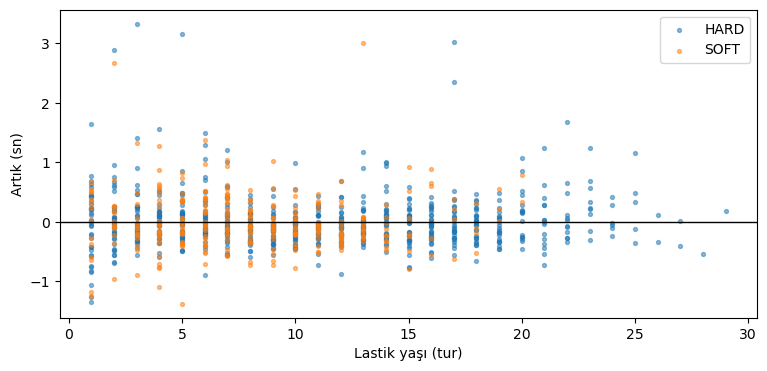

In [9]:
import matplotlib.pyplot as plt

clean = clean.assign(resid=model.resid)
fig, ax = plt.subplots(figsize=(9, 4))
for comp, g in clean.groupby("compound"):
    ax.scatter(g.tyre_life, g.resid, s=8, alpha=0.5, label=comp)
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("Lastik yaşı (tur)")
ax.set_ylabel("Artık (sn)")
ax.legend()
plt.show()

In [10]:
import json, os

out = {
    "deg_per_lap": {
        "HARD": float(model.params["tyre_life:C(compound)[HARD]"]),
        "SOFT": float(model.params["tyre_life:C(compound)[SOFT]"]),
    },
    "deg_se": {
        "HARD": float(model.bse["tyre_life:C(compound)[HARD]"]),
        "SOFT": float(model.bse["tyre_life:C(compound)[SOFT]"]),
    },
    "fuel_per_lap": float(model.params["lap_number"]),
    "lap_sigma": float(model.scale ** 0.5),
}
os.makedirs(os.path.expanduser("~/f1-strategy/data/processed"), exist_ok=True)
with open(os.path.expanduser("~/f1-strategy/data/processed/bahrain_2024_params.json"), "w") as f:
    json.dump(out, f, indent=2)
print(out)

{'deg_per_lap': {'HARD': 0.11050864247659703, 'SOFT': 0.12992335901457774}, 'deg_se': {'HARD': 0.0030397913802296113, 'SOFT': 0.006583256034989563}, 'fuel_per_lap': -0.07106015015763446, 'lap_sigma': 0.4585957835068989}


In [14]:
import os
export = clean[["driver_number", "lap_number", "lap_duration", "compound", "tyre_life"]].copy()
export["compound_kod"] = export.compound.map({"SOFT": 1, "HARD": 2})
path = os.path.expanduser("~/f1-strategy/data/processed/bahrain_2024_clean.csv")
export.to_csv(path, index=False)